# Studenten gaan geld verdienen ..
We gaan een portfolio maken via Yahoo Finance (https://finance.yahoo.com/) en de FED in St. Louis (https://fred.stlouisfed.org/categories).

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

# Aandelen, obligatie en crypto's
Alle libraries geinstalleerd, nu de data:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Portfolio

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gevuld = portfolio_gefilterd.ffill()
portfolio_gevuld

Price,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Ticker,AAPL_Apple,SHEL_Shell,NOC_Northrop,TSM_TSMC,RIO_RioTinto,GE_GE,GS_GoldmanSachs,BOND_Bond,BTC-USD_Bitcoin,XRP-USD_Ripple
Date,,,,,,,,,,
2018-05-01,39.847034,50.096256,273.995392,32.430241,29.978445,64.199776,201.957397,79.888062,9119.009766,0.841407
2018-05-02,41.607277,50.190559,273.941772,31.447239,30.231186,64.793800,199.721710,79.849098,9235.919922,0.859094
2018-05-03,41.682671,50.502537,281.540314,31.738806,30.472950,63.651436,199.175522,79.841362,9743.860352,0.884466
2018-05-04,43.318020,50.669392,279.908234,32.147007,30.560862,64.428238,200.481171,79.942520,9700.759766,0.895442
2018-05-05,43.318020,50.669392,279.908234,32.147007,30.560862,64.428238,200.481171,79.942520,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,168.283661,69.643875,472.327179,136.391861,63.981560,161.272690,418.341431,84.381561,63755.320312,0.526112
2024-04-27,168.283661,69.643875,472.327179,136.391861,63.981560,161.272690,418.341431,84.381561,63419.140625,0.517775


# Grondstoffen
https://tradingeconomics.com/commodities

In [ ]:
graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

#kobalt
#silicium

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Sowieso toe te voegen aan deze tabellen: is dit een prijs per dag? In welke eenheid? Per m3 of liter of vat of ..

## Portfolio

In [ ]:
grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen], axis=1)
grondstoffen_1.columns = ["Graan", "Koffie", "Vlees", "Gas", "Kolen"]
grondstoffen_1

,Graan,Koffie,Vlees,Gas,Kolen
DATE,,,,,
2018-05-01,192.70383,194.200,188.000000,NaN,595.400
2018-05-07,NaN,NaN,NaN,2.845,NaN
2018-05-14,NaN,NaN,NaN,2.873,NaN
2018-05-21,NaN,NaN,NaN,2.923,NaN
2018-05-28,NaN,NaN,NaN,2.962,NaN
...,...,...,...,...,...
2024-04-08,NaN,NaN,NaN,3.591,NaN
2024-04-15,NaN,NaN,NaN,3.628,NaN
2024-04-22,NaN,NaN,NaN,3.668,NaN


In [ ]:
grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Olie", "Goud", "Palladium"]
grondstoffen_2

,Olie,Goud,Palladium
Date,,,
2018-05-01,67.250000,1303.800049,938.450012
2018-05-02,67.930000,1302.599976,962.349976
2018-05-03,68.430000,1310.699951,960.900024
2018-05-04,69.720001,1312.699951,959.450012
2018-05-07,70.730003,1312.199951,964.299988
...,...,...,...
2024-04-24,82.809998,2324.500000,1007.400024
2024-04-25,83.570000,2329.800049,981.099976
2024-04-26,83.849998,2334.800049,957.400024


In [ ]:
grondstoffen_portfolio = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_portfolio = grondstoffen_portfolio.ffill()
grondstoffen_portfolio

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,192.703830,194.200,188.000000,NaN,595.400,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000000,NaN,595.400,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000000,NaN,595.400,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000000,NaN,595.400,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


# Hoe kun je de portfolio- en de grondstoffendata samenvoegen?
Via een concat:

In [ ]:
portfolio_compleet = pd.concat([portfolio_gevuld, grondstoffen_portfolio], axis=1)
portfolio_compleet = portfolio_compleet.ffill()
portfolio_compleet = portfolio_compleet.loc[portfolio_compleet.loc[:, "Gas"] > 0, :]
portfolio_compleet

,"(Close_Apple, AAPL_Apple)","(Close_Shell, SHEL_Shell)","(Close_Northrop, NOC_Northrop)","(Close_TSMC, TSM_TSMC)","(Close_RioTinto, RIO_RioTinto)","(Close_GE, GE_GE)","(Close_GoldmanSachs, GS_GoldmanSachs)","(Close_Bond, BOND_Bond)","(Close_Bitcoin, BTC-USD_Bitcoin)","(Close_Ripple, XRP-USD_Ripple)",Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,43.631420,50.589584,282.833527,32.030376,30.483934,64.291145,202.409637,79.950317,9373.009766,0.832641,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,43.841141,50.807262,293.660645,32.638493,30.445480,65.205032,202.238983,79.849098,9234.820312,0.813970,192.703830,194.200,188.000000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,44.149841,52.026104,292.162292,32.780102,31.077356,66.804306,206.275269,79.732361,9325.179688,0.802043,192.703830,194.200,188.000000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,44.781361,52.217236,291.110016,33.129986,31.511423,67.124161,207.734497,79.825775,9043.940430,0.758237,192.703830,194.200,188.000000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,44.611042,52.922977,290.119995,33.246613,31.533407,66.712921,207.290695,79.926987,8441.490234,0.684948,192.703830,194.200,188.000000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,168.283661,69.643875,472.327179,136.391861,63.981560,161.272690,418.341431,84.381561,63419.140625,0.517775,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-28,168.283661,69.643875,472.327179,136.391861,63.981560,161.272690,418.341431,84.381561,63113.230469,0.510377,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,172.458450,69.501312,477.999603,136.589111,64.703506,163.398483,421.511505,84.712952,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,169.307480,68.113556,476.829742,135.445114,63.597149,160.746216,417.500000,84.438370,60636.855469,0.500065,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


# Data naar Excel exporteren
Als je data naar Excel wilt exporteren, gebruik dan onderstaand commando:

In [ ]:
portfolio_compleet.to_excel('portfolio.xlsx', index=True)

Let Op: het bestand dat je exporteert, komt te staan in de map ' content':<br>
zie menu helemaal links, klik op het onderste ' Bestanden'-icoontje en kijk in de map ' content'.

# Voorspellen

In [ ]:
start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

oil = yf.download('CL=F', start, end).tz_localize(None) #olie
oil = oil.add_suffix("_Olie")
oil = oil.loc[:,['Close_Olie']]
oil.head()

[*********************100%***********************]  1 of 1 completed


Price,Close_Olie
Ticker,CL=F_Olie
Date,
2018-05-01,67.250000
2018-05-02,67.930000
2018-05-03,68.430000
2018-05-04,69.720001
2018-05-07,70.730003


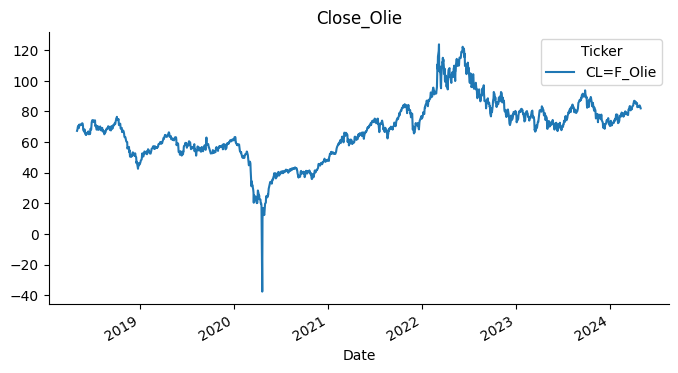

In [ ]:
from matplotlib import pyplot as plt
oil['Close_Olie'].plot(kind='line', figsize=(8, 4), title='Close_Olie')
plt.gca().spines[['top', 'right']].set_visible(False)

## Moving Average
https://en.wikipedia.org/wiki/Moving_average

In [ ]:
window_size = 3
oil_MA = oil
oil_MA['Moving Average'] = oil_MA['Close_Olie'].rolling(window=window_size).mean()
oil_MA

Price,Close_Olie,Moving Average
Ticker,CL=F_Olie,
Date,,
2018-05-01,67.250000,NaN
2018-05-02,67.930000,NaN
2018-05-03,68.430000,67.870000
2018-05-04,69.720001,68.693334
2018-05-07,70.730003,69.626668
...,...,...
2024-04-24,82.809998,83.006666
2024-04-25,83.570000,83.246666


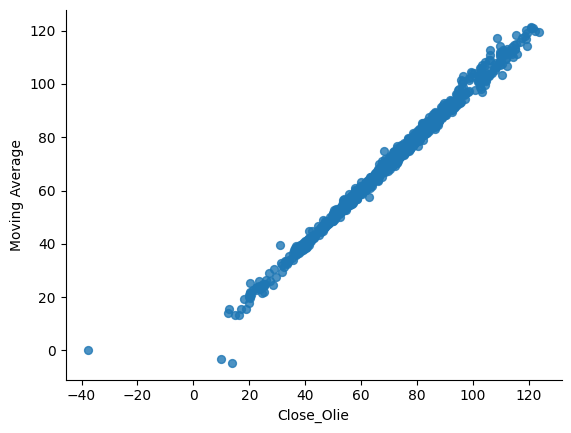

In [ ]:
from matplotlib import pyplot as plt
oil.plot(kind='scatter', x='Close_Olie', y='Moving Average', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
from sklearn.metrics import mean_squared_error

# oil_MA contains the original 'Close_Olie' and the 'Moving Average'
# The 'Moving Average' column will have NaN values at the beginning due to the rolling window
# We need to drop these NaN values to calculate MSE
oil_MA_cleaned = oil_MA.dropna()

# Extract the actual values and the predicted values (Moving Average)
actual_values = oil_MA_cleaned['Close_Olie']
predicted_values = oil_MA_cleaned['Moving Average']

# Calculate the Mean Squared Error
mse_MA = mean_squared_error(actual_values, predicted_values)

print(f"Mean Squared Error for Moving Average: {mse_MA}")

Mean Squared Error for Moving Average: 3.0998171292331187


## Weighted Moving Average
A weighted moving average (WMA) is a type of moving average that assigns a greater weight to more recent data points. This makes it more responsive to new information compared to a simple moving average.

In [ ]:
window_size = 3
# Example weights for a window of size 3 (sum must be 1)
weights = [0.2, 0.3, 0.5]

# Ensure the window size and number of weights match
if len(weights) != window_size:
    raise ValueError("Number of weights must match window size")

# Define a function to calculate the weighted sum
def weighted_sum(data, weights):
    return (data * weights).sum()

# Calculate the weighted moving average
oil_WMA = oil.copy()
oil_WMA['Weighted Moving Average'] = oil_WMA['Close_Olie'].rolling(window=window_size).apply(lambda x: weighted_sum(x, weights), raw=True)

oil_WMA

Price,Close_Olie,Moving Average,Weighted Moving Average
Ticker,CL=F_Olie,,
Date,,,
2018-05-01,67.250000,NaN,NaN
2018-05-02,67.930000,NaN,NaN
2018-05-03,68.430000,67.870000,68.044000
2018-05-04,69.720001,68.693334,68.975001
2018-05-07,70.730003,69.626668,69.967002
...,...,...,...
2024-04-24,82.809998,83.006666,82.982999
2024-04-25,83.570000,83.246666,83.299999


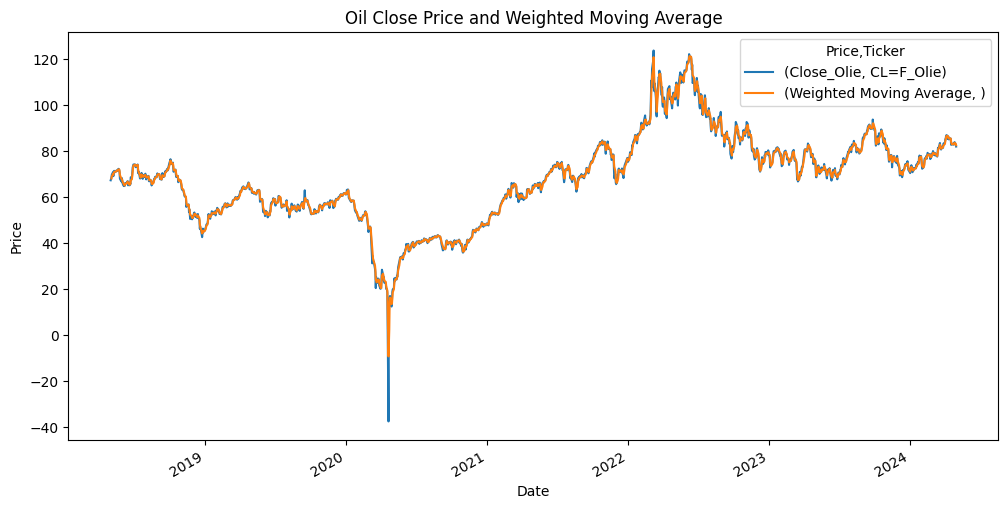

In [ ]:
from matplotlib import pyplot as plt

oil_WMA[['Close_Olie', 'Weighted Moving Average']].plot(figsize=(12, 6))
plt.title('Oil Close Price and Weighted Moving Average')
plt.xlabel('Date')
plt.ylabel('Price')
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error

# oil_WMA contains the original 'Close_Olie' and the 'Weighted Moving Average'
# The 'Weighted Moving Average' column will have NaN values at the beginning due to the rolling window
# We need to drop these NaN values to calculate MSE
oil_WMA_cleaned = oil_WMA.dropna()

# Extract the actual values and the predicted values (Weighted Moving Average)
actual_values_wma = oil_WMA_cleaned['Close_Olie']
predicted_values_wma = oil_WMA_cleaned['Weighted Moving Average']

# Calculate the Mean Squared Error
mse_WMA = mean_squared_error(actual_values_wma, predicted_values_wma)

print(f"Mean Squared Error for Weighted Moving Average: {mse_WMA}")

Mean Squared Error for Weighted Moving Average: 1.6684667424292619


## Optimized Weighted Moving Average
You can optimize your weighted moving average.<br>The current implementation uses fixed weights. To optimize it, you would typically find the weights that minimize an error metric, like the Mean Squared Error (MSE), between the predicted values and the actual values.

In [ ]:
from scipy.optimize import minimize

# Assume 'oil' is your pandas DataFrame with a 'Close_Olie' column
# Assume window_size is defined

def weighted_sum(data, weights):
    return (data * weights).sum()

def objective_function(weights, data, window_size):
    # Ensure weights sum to 1 (optional, but good practice)
    weights = weights / weights.sum()

    # Calculate the weighted moving average
    wma = data.rolling(window=window_size).apply(lambda x: weighted_sum(x, weights), raw=True)

    # Calculate the error (e.g., Mean Squared Error)
    # We need to align the WMA with the actual data for comparison
    error = ((data - wma)**2).mean()

    return error

# Initial guess for weights (e.g., equal weights)
initial_weights = np.ones(window_size) / window_size

# Define constraints for the weights (optional: weights sum to 1, weights are non-negative)
constraints = ({'type': 'eq', 'fun': lambda w: w.sum() - 1})
bounds = [(0, None) for _ in range(window_size)] # Weights should be non-negative

# Run the optimization
result = minimize(objective_function, initial_weights, args=(oil['Close_Olie'], window_size),
                  method='SLSQP', constraints=constraints, bounds=bounds)

optimized_weights = result.x
min_error = result.fun

print("Optimized Weights:", optimized_weights)
print("Mean Squared Error for Optimized WMA):", min_error)

# Now you can calculate the WMA with the optimized weights
oil_optimized_WMA = oil.copy()
oil_optimized_WMA['Optimized Weighted Moving Average'] = oil_optimized_WMA['Close_Olie'].rolling(window=window_size).apply(lambda x: weighted_sum(x, optimized_weights), raw=True)

# You can then visualize or use oil_optimized_WMA for further analysis

Optimized Weights: [0. 0. 1.]
Mean Squared Error for Optimized WMA): 0.0


This code defines an objective function that calculates the Mean Squared Error for a given set of weights. It then uses scipy.optimize.minimize with the SLSQP method to find the weights that minimize this function, subject to the constraint that the weights sum to 1 and are non-negative.

Remember that optimization results can be sensitive to the initial guess and the chosen optimization method. You might need to experiment with different methods and parameters to find the best results for your specific data.

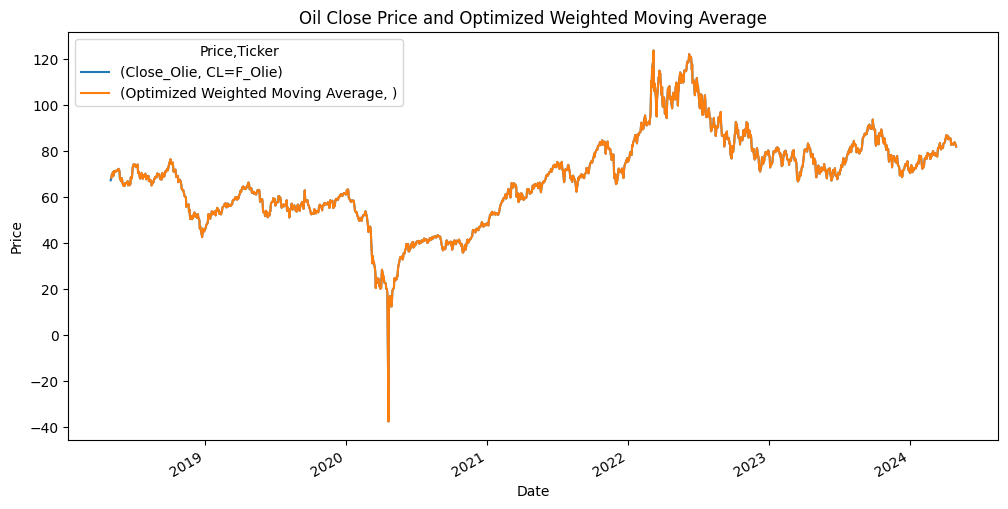

In [ ]:
import matplotlib.pyplot as plt

# Assuming you have calculated oil_optimized_WMA as shown in the previous steps

# Plot the original close prices and the optimized weighted moving average
oil_optimized_WMA[['Close_Olie', 'Optimized Weighted Moving Average']].plot(figsize=(12, 6))

# Add title and labels
plt.title('Oil Close Price and Optimized Weighted Moving Average')
plt.xlabel('Date')
plt.ylabel('Price')

# Show the plot
plt.show()

## Exponential Smoothing
Exponential smoothing is a forecasting method that uses a weighted average of past observations to predict future values. It gives exponentially decreasing weights to older observations, meaning more recent data has a greater influence on the forecast.

There are different types of exponential smoothing, including:

<ul><li><b>Simple Exponential Smoothing:</b> Suitable for data with no trend or seasonality. It only uses a smoothing level parameter (alpha) to weight the observations.</li>
<li><b>Double Exponential Smoothing (Holt's method):</b> Suitable for data with a trend but no seasonality. It adds a trend parameter (beta) to account for the increasing or decreasing pattern in the data.</li>
<li><b>Triple Exponential Smoothing (Holt-Winters method):</b> Suitable for data with both trend and seasonality. It adds a seasonal parameter (gamma) to account for recurring patterns.</li></ul>


https://en.wikipedia.org/wiki/Exponential_smoothing

In [ ]:
oil['Close_Olie']

Ticker,CL=F_Olie
Date,
2018-05-01,67.250000
2018-05-02,67.930000
2018-05-03,68.430000
2018-05-04,69.720001
2018-05-07,70.730003
...,...
2024-04-24,82.809998
2024-04-25,83.570000
2024-04-26,83.849998


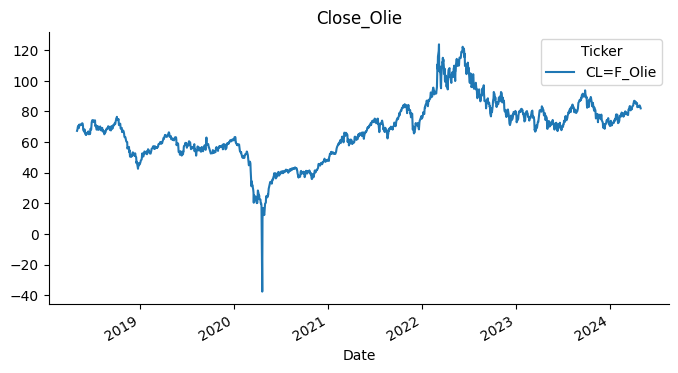

In [ ]:
from matplotlib import pyplot as plt
oil['Close_Olie'].plot(kind='line', figsize=(8, 4), title='Close_Olie')
plt.gca().spines[['top', 'right']].set_visible(False)

We are using SimpleExpSmoothing from the statsmodels library to perform exponential smoothing on the oil price data. <br>This method is appropriate if we assume that the oil price data does not have a significant trend or seasonality, or if we want to model and forecast the data based on its level alone.

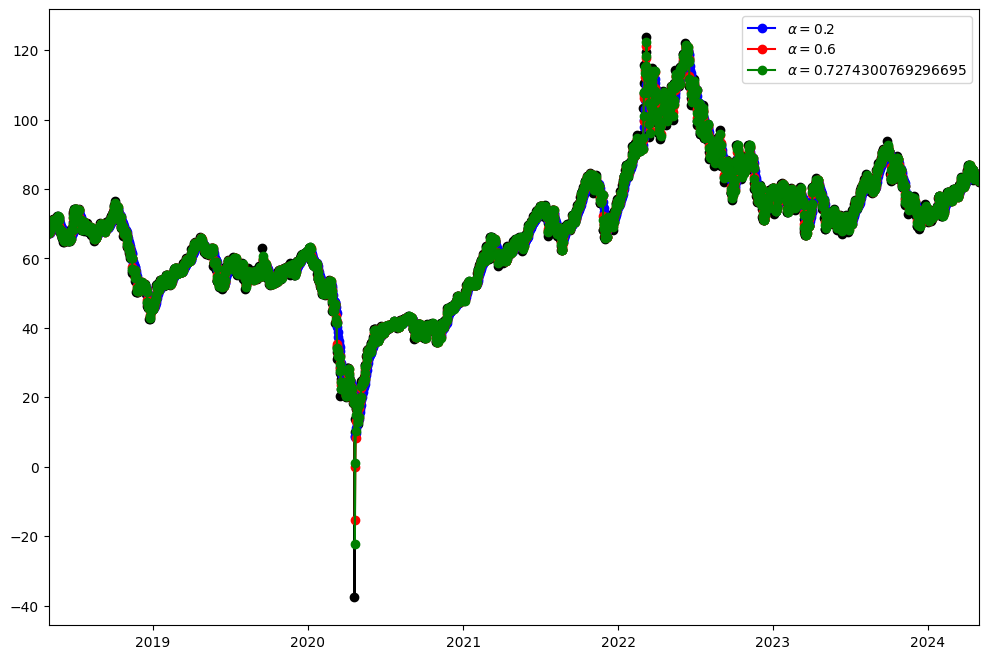

In [ ]:
from statsmodels.tsa.api import SimpleExpSmoothing
import matplotlib.pyplot as plt
import pandas as pd

# Assuming 'oil' DataFrame is loaded and contains a 'Close_Olie' column

# Ensure the index is a DatetimeIndex
oil.index = pd.to_datetime(oil.index)

# Create a complete daily date range
full_date_range = pd.date_range(start=oil.index.min(), end=oil.index.max(), freq='D')

# Reindex the oil DataFrame to the full date range and forward fill missing values
oil_reindexed = oil.reindex(full_date_range).ffill()

# Now set the frequency on the reindexed DataFrame
oil_reindexed.index.freq = 'D'

# Use the reindexed DataFrame for SimpleExpSmoothing
fit1 = SimpleExpSmoothing(oil_reindexed['Close_Olie'], initialization_method="heuristic").fit(smoothing_level=0.2, optimized=False)
fcast1 = fit1.forecast(3).rename(r"$\alpha=0.2$")

fit2 = SimpleExpSmoothing(oil_reindexed['Close_Olie'], initialization_method="heuristic").fit(smoothing_level=0.6, optimized=False)
fcast2 = fit2.forecast(3).rename(r"$\alpha=0.6$")

fit3 = SimpleExpSmoothing(oil_reindexed['Close_Olie'], initialization_method="estimated").fit()
fcast3 = fit3.forecast(3).rename(r"$\alpha=%s$" % fit3.model.params["smoothing_level"])

plt.figure(figsize=(12, 8))
plt.plot(oil_reindexed['Close_Olie'], marker="o", color="black")

plt.plot(fit1.fittedvalues, marker="o", color="blue")
(line1,) = plt.plot(fcast1, marker="o", color="blue")
plt.plot(fit2.fittedvalues, marker="o", color="red")
(line2,) = plt.plot(fcast2, marker="o", color="red")
plt.plot(fit3.fittedvalues, marker="o", color="green")
(line3,) = plt.plot(fcast3, marker="o", color="green")

plt.legend([line1, line2, line3], [fcast1.name, fcast2.name, fcast3.name])

# Set the x-axis limits - use the index of the reindexed DataFrame
plt.xlim(oil_reindexed.index.min(), oil_reindexed.index.max()) # Use min/max index from reindexed data

plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error
import pandas as pd

# Assuming 'oil_reindexed' DataFrame is available and 'fit3' is your fitted model

# The actual values are the original 'Close_Olie' from the reindexed data
actual_values_es = oil_reindexed['Close_Olie']

# The predicted values are the fitted values from the exponential smoothing model
predicted_values_es = fit3.fittedvalues

# Ensure the actual and predicted values are aligned by index
# This is important if there were any missing values in the original data before reindexing
# In this case, since you reindexed and ffilled, they should be aligned.

# Calculate the Mean Squared Error
mse_ES = mean_squared_error(actual_values_es, predicted_values_es)

print(f"Mean Squared Error for Exponential Smoothing: {mse_ES}")

Mean Squared Error for Exponential Smoothing: 4.405204240242866


Here we run three variants of simple exponential smoothing:<br>
1. In fit1 we do not use the auto optimization but instead choose to explicitly provide the model with the parameter alpha = 0.2 (alpha = the smoothing constant).
2. In fit2 as above we choose an alpha = 0.6.
3. In fit3 we allow statsmodels to automatically find an optimized value for us.


https://www.statsmodels.org/dev/examples/notebooks/generated/exponential_smoothing.html